# Metrics Analysis

**Exploration : Combat : Decisions : Progression**

This notebook turns local recordings into tables and charts. It opens with **dummy data** from `test_data` so the calculations can be checked without running the game.

**Quick start:** choose the input folder below, then select **Run All**. Calculation code is shared with the terminal exporter through `metrics_analysis.py`. Install Python 3.10+ and the packages in `requirements.txt`.

| Measurement | Definition |
|---|---|
| Rooms visited / completed | Unique room IDs per recording history and attempt; entries also count revisits |
| Combat Progression | Victories and damage per attempt |
| Decision time | Active seconds for confirmed decisions, grouped by context |
| Attempts to boss | Distinct observed attempts up to the first arrival, per recording history |


## 1. Configuration

Set `DATA_DIR` to the recordings folder reported by **MetricsRecorder &rarr; Print metrics file path**. Use `GAME_VERSION` to inspect one build. Leave `EXPORT = False` to explore without writing CSV files.


In [1]:
# Change DATA_DIR to switch from the included samples to real recordings.
# --- CONFIGURATION ---
from pathlib import Path
import sys
import tempfile

candidates = [Path.cwd(), Path.cwd() / 'Tools/Metrics',
              Path.cwd() / 'LABAGI/Tools/Metrics']
TOOL_DIR = next((p for p in candidates if (p / 'metrics_analysis.py').exists()), None)
if TOOL_DIR is None:
    raise FileNotFoundError('Open the notebook from Tools/Metrics or the project root.')
sys.path.insert(0, str(TOOL_DIR))

DATA_DIR = TOOL_DIR / 'test_data'
GAME_VERSION = None  # Example: 'demo-1.0'; None includes all versions
EXPORT = False
OUTPUT_DIR = Path(tempfile.gettempdir()) / 'MetricsAnalysis'


In [2]:
# Shared formatting keeps the tables and charts consistent.
# --- PRESENTATION ---
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown
# Reload after source changes when reusing an existing notebook kernel.
import importlib
import metrics_analysis
importlib.reload(metrics_analysis)
from metrics_analysis import analyze, load_records

plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 120,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.labelcolor': '#334155',
    'text.color': '#0f172a', 'font.size': 10, 'figure.facecolor': 'white'})
BLUE, TEAL, AMBER = '#3563ad', '#167d8d', '#c58b32'

def table(frame, formats=None):
    # Leave table styling to Jupyter's default renderer.
    display(frame)


def finish(ax, title, ylabel):
    ax.set_title(title, loc='left', pad=15)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()


## 2. Data Quality

Malformed lines and duplicate session/sequence pairs are reported. A decision without an end is **incomplete**. A history without a boss arrival remains **not reached**. Missing events do not prove that a feature was used or that its measured result was zero.


In [3]:
# Inspect coverage and warnings before interpreting the measurements.
records, read_warnings = load_records(DATA_DIR)
if GAME_VERSION is not None:
    records = [row for row in records if row['gameVersion'] == GAME_VERSION]

result = analyze(records, read_warnings)
is_demo = DATA_DIR.resolve() == (TOOL_DIR / 'test_data').resolve()

display(Markdown('**DUMMY DATA : demonstration**' if is_demo else '**Data from the selected folder**'))
print(f'{len(records)} records : {len({r["sessionId"] for r in records})} sessions')
print('Versions:', ', '.join(sorted({r['gameVersion'] for r in records})) or 'no data')

table(pd.DataFrame(sorted(result['coverage'].items()), columns=['Event', 'Records']))
if result['warnings']:
    print('Warnings to review:')
    for warning in result['warnings']:
        print(' •', warning)
else:
    print('No read or consistency warnings in the selected records.')
    
open_sessions = {r['sessionId'] for r in records if r['eventName'] == 'session.started'} - {
    r['sessionId'] for r in records if r['eventName'] == 'session.ended'}
print('Sessions without a recorded end:', len(open_sessions))


**DUMMY DATA : demonstration**

125 records : 3 sessions
Versions: demo-1.0


,Event,Records
0,boss.reached,1
1,combat.ended,7
2,damage.dealt,7
3,damage.received,7
4,decision.ended,13
5,decision.started,14
6,exploration.started,5
7,feedback.played,7
8,help.requested,12
9,panel.closed,7


No read or consistency warnings in the selected records.
Sessions without a recorded end: 1


## 3. Room Exploration

`room.entered` records an entry; `room.completed` records the room's completion condition. Each room ID counts once per attempt, while the entry count includes revisits. Summing attempts measures total room exposure, not the number of different rooms in the map.


,gameVersion,runId,entries,visited,completed
0,demo-1.0,a-01,3,2,2
1,demo-1.0,a-02,2,2,1
2,demo-1.0,a-03,3,3,3
3,demo-1.0,b-01,2,2,1
4,demo-1.0,b-02,2,2,2


Visited: 11 : Completed: 9 : Entries: 12


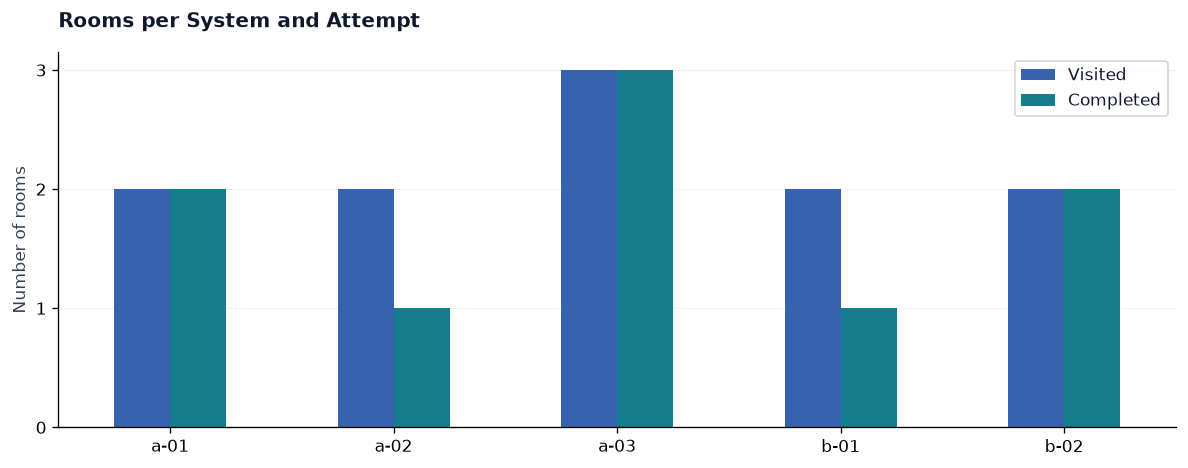

In [4]:
# Count room IDs once per attempt; keep repeated entries separately.
rooms = pd.DataFrame(result['rooms'])
if rooms.empty:
    display(Markdown('No attempts with a recorded start.'))
else:
    table(rooms)
    print(f"Visited: {rooms.visited.sum()} : Completed: {rooms.completed.sum()} : Entries: {rooms.entries.sum()}")
    labels = rooms['runId']
    ax = rooms.set_axis(labels)[['visited', 'completed']].rename(
        columns={'visited': 'Visited', 'completed': 'Completed'}).plot.bar(color=[BLUE, TEAL], rot=0)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    finish(ax, 'Rooms per System and Attempt', 'Number of rooms')


## 4. Combat Progression

Each combat has a boolean victory result. Count those results once across the selected history to obtain cumulative victories by attempt. The first three attempts contain 1, 0 and 2 victories, giving cumulative totals of 1, 1 and 3. Damage events identify the combat as subject; missing measurements remain unavailable.


,gameVersion,runId,attempt,cumulativeVictories,defeats,combats,damageDealt,damageReceived
0,demo-1.0,a-01,1,1,1,2,45,33
1,demo-1.0,a-02,2,1,1,1,15,25
2,demo-1.0,a-03,3,3,0,2,60,16
3,demo-1.0,b-01,4,3,1,1,15,25
4,demo-1.0,b-02,5,4,0,1,30,8


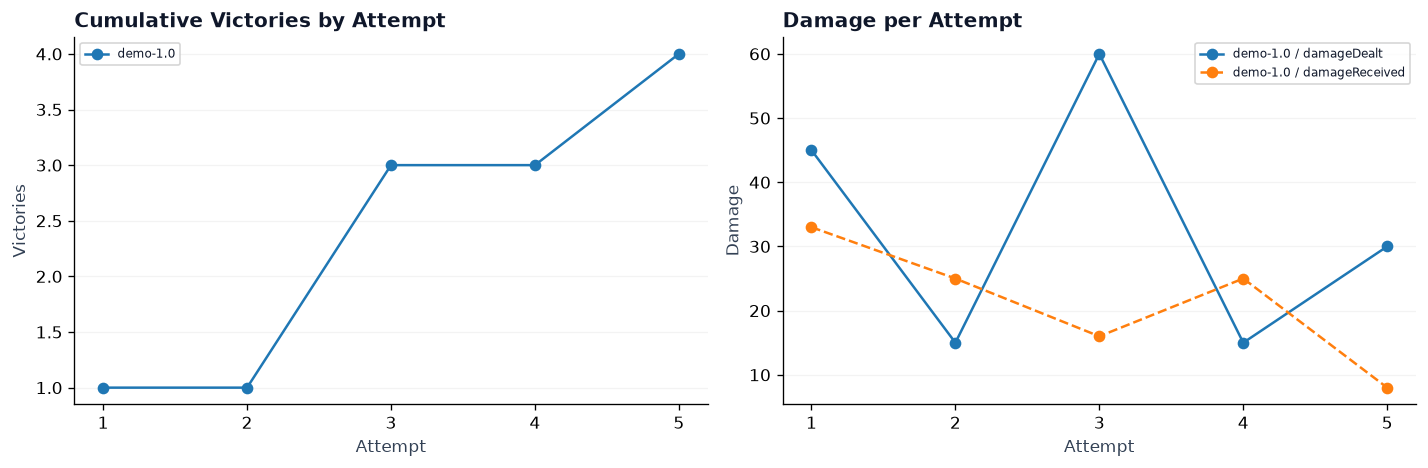

In [5]:
# Count victories within each attempt, then compare successive attempts.
combats = pd.DataFrame(result['combats'])
progression = pd.DataFrame(result['progression'])
if progression.empty:
    display(Markdown('No recorded attempts.'))
else:
    table(progression)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for keys, group in progression.groupby(['gameVersion']):
        label = keys[0] if isinstance(keys, tuple) else str(keys)
        axes[0].plot(group.attempt, group.cumulativeVictories, marker='o', label=label)
        # Plot only measurements actually recorded for this attempt.
        for column, style in [('damageDealt', '-'), ('damageReceived', '--')]:
            available = group.dropna(subset=[column])
            if not available.empty:
                axes[1].plot(available.attempt, available[column], style, marker='o', label=label + ' / ' + column)
    for ax, title, ylabel in zip(axes, ['Cumulative Victories by Attempt', 'Damage per Attempt'], ['Victories', 'Damage']):
        ax.set_title(title, loc='left')
        ax.set_xlabel('Attempt')
        ax.set_ylabel(ylabel)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis='y', alpha=.15)
        if ax.lines:
            ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()


## 5. Decision Time

Contexts are configurable: `path`, `card`, `target`, `reward`, or another name. The recorder measures active time from making a choice available to confirming it, subtracting explicit pauses. Cancelled and incomplete decisions are shown separately and are excluded from confirmed-time averages and medians.


,gameVersion,context,confirmed,cancelled,incomplete,meanSeconds,medianSeconds
0,demo-1.0,card,3,1,0,7.200000,4.3
1,demo-1.0,path,3,0,1,5.066667,3.2
2,demo-1.0,reward,3,0,0,9.533333,6.7
3,demo-1.0,target,3,0,0,4.100000,2.8


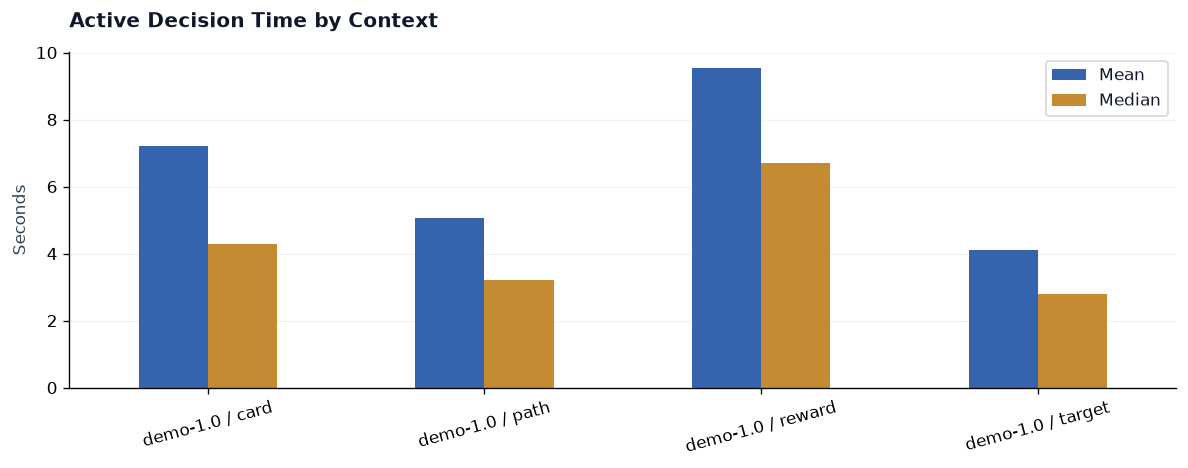

Overall mean for 12 confirmed decisions: 6.47 s


,sessionId,runId,context,outcome,seconds
0,demo-session-01,a-01,path,confirmed,1.4
1,demo-session-01,a-01,card,confirmed,2.1
2,demo-session-01,a-01,card,cancelled,99.0
3,demo-session-01,a-02,path,confirmed,3.2
4,demo-session-01,a-02,card,confirmed,4.3
5,demo-session-02,a-03,path,confirmed,10.6
6,demo-session-02,a-03,card,confirmed,15.2
7,demo-session-02,a-03,reward,confirmed,3.5
8,demo-session-02,a-03,target,confirmed,0.9
9,demo-session-02,a-03,reward,confirmed,6.7


In [6]:
# Only confirmed decisions contribute to mean and median durations.
decisions = pd.DataFrame(result['decisions'])
summary = pd.DataFrame(result['decision_summary'])
if summary.empty:
    display(Markdown('No recorded decisions.'))
else:
    table(summary, {'meanSeconds': '{:.2f}', 'medianSeconds': '{:.2f}'})
    confirmed = decisions[decisions.outcome == 'confirmed']
    if not confirmed.empty:
        labels = summary.gameVersion + ' / ' + summary.context
        chart = summary.set_axis(labels)[['meanSeconds', 'medianSeconds']].dropna(how='all')
        ax = chart.rename(columns={'meanSeconds': 'Mean', 'medianSeconds': 'Median'}).plot.bar(
            color=[BLUE, AMBER], rot=15)
        finish(ax, 'Active Decision Time by Context', 'Seconds')
        print(f'Overall mean for {len(confirmed)} confirmed decisions: {confirmed.seconds.mean():.2f} s')
    table(decisions[['sessionId', 'runId', 'context', 'outcome', 'seconds']], {'seconds': '{:.2f}'})


## 6. Attempts to Reach the Boss

Use a new run ID for each attempt and keep it when resuming. The selected folder represents one local recording history. Attempts are ordered across sessions within each game version. The count includes the attempt that reaches the boss. Without a recorded arrival, the result stays unavailable. Load the full history from its beginning.


,gameVersion,attemptsObserved,reachedBoss,attemptsToBoss
0,demo-1.0,5,True,3


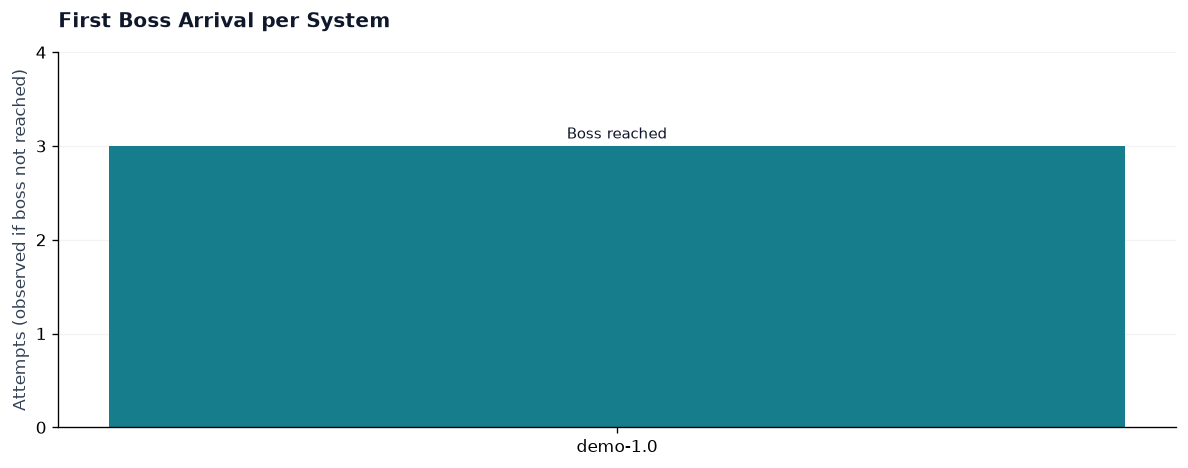

In [7]:
# An unfinished system shows observed attempts, not a completed arrival count.
attempts = pd.DataFrame(result['attempts'])
if attempts.empty:
    display(Markdown('No observable systems or attempts.'))
else:
    table(attempts, {'attemptsToBoss': '{:.0f}'})
    labels = attempts.gameVersion
    values = [row.attemptsToBoss if row.reachedBoss else row.attemptsObserved
              for row in attempts.itertuples()]
    colors = [TEAL if reached else AMBER for reached in attempts.reachedBoss]
    fig, ax = plt.subplots()
    bars = ax.bar(labels, values, color=colors)
    ax.set_ylim(0, max(values, default=1) + 1)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    for bar, reached in zip(bars, attempts.reachedBoss):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.08,
                'Boss reached' if reached else 'Not reached yet', ha='center', fontsize=9)
    finish(ax, 'First Boss Arrival per System', 'Attempts (observed if boss not reached)')


## Signal Activity

Signals are identified by `eventKind = signal`. The table counts occurrences by version, session and event name; the chart shows activity over session time. These records describe notifications, not numeric measurements. Older files without eventKind remain unclassified.


,gameVersion,sessionId,eventName,count
0,demo-1.0,demo-session-01,exploration.started,2
1,demo-1.0,demo-session-01,feedback.played,3
2,demo-1.0,demo-session-01,help.requested,5
3,demo-1.0,demo-session-01,panel.closed,3
4,demo-1.0,demo-session-01,panel.opened,4
5,demo-1.0,demo-session-02,exploration.started,1
6,demo-1.0,demo-session-02,feedback.played,2
7,demo-1.0,demo-session-02,help.requested,4
8,demo-1.0,demo-session-02,panel.closed,2
9,demo-1.0,demo-session-02,panel.opened,3


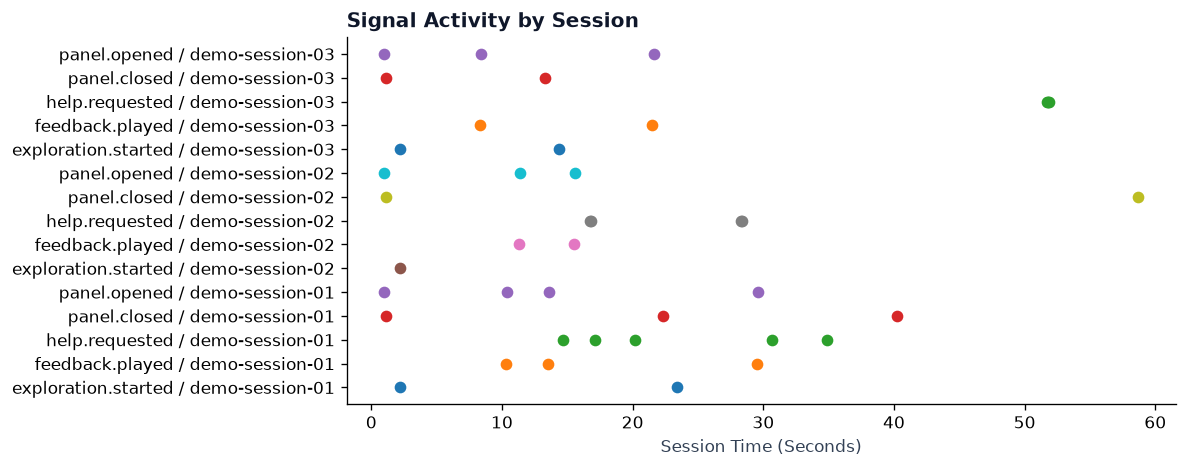

In [8]:
# Group notifications by their recorded identity, without guessing from empty payloads.
signals = pd.DataFrame(result['signals'])
signal_summary = pd.DataFrame(result['signal_summary'])
if signals.empty:
    display(Markdown('No explicitly recorded Signals in this selection.'))
else:
    table(signal_summary)
    fig, ax = plt.subplots()
    for (session, event), group in signals.groupby(['sessionId', 'eventName']):
        ax.scatter(group.elapsedSeconds, [event + ' / ' + session] * len(group), label=event)
    ax.set_title('Signal Activity by Session', loc='left')
    ax.set_xlabel('Session Time (Seconds)')
    plt.tight_layout()
    plt.show()


## 7. Check the Test Data

Known totals make the dummy dataset a repeatable check of the calculations. These assertions apply only to the complete, unfiltered sample dataset.


In [9]:
# These known totals catch calculation changes when running the sample dataset.
import json
if is_demo and GAME_VERSION is None:
    expected = json.loads((TOOL_DIR / 'test_data/expected.json').read_text())
    assert len({r['sessionId'] for r in records}) == expected['sessions']
    assert len(rooms) == expected['runs']
    assert rooms.entries.sum() == expected['roomEntries']
    assert rooms.visited.sum() == expected['roomsVisited']
    assert rooms.completed.sum() == expected['roomsCompleted']
    assert len(combats) == expected['combats'] and combats.victory.sum() == expected['victories']
    assert (decisions.outcome == 'confirmed').sum() == expected['confirmedDecisions']
    assert (decisions.outcome == 'cancelled').sum() == expected['cancelledDecisions']
    assert (decisions.outcome == 'incomplete').sum() == expected['incompleteDecisions']
    assert abs(decisions.loc[decisions.outcome == 'confirmed', 'seconds'].mean() - expected['meanDecisionSeconds']) < 1e-9
    for row in result['attempts']:
        assert row['attemptsToBoss'] == expected['attemptsToBoss']
    print('Dummy data: all counts and calculations match the expected results.')
else:
    print('Sample assertions do not apply to the current selection.')


Dummy data: all counts and calculations match the expected results.


## 8. Export and Interpretation

CSV export includes events, rooms, combats, progression, decisions, decision summaries, attempts, Signals and Signal summaries, plus warnings. The original JSONL files are preserved. Export uses the full input folder; `GAME_VERSION` filters only this notebook's views.

Use the results as measurable evidence for evaluation. Consider the game version, sample size, decision context and completeness of the recordings when drawing conclusions.


In [10]:
# Export is opt-in and reads the full folder, independently of the view filter.
if EXPORT:
    from export_metrics import export
    count, warnings = export(DATA_DIR, OUTPUT_DIR)
    print(f'{count} records exported to {OUTPUT_DIR}; {len(warnings)} warnings.')
else:
    print('Export disabled. Set EXPORT = True to generate CSV files.')


Export disabled. Set EXPORT = True to generate CSV files.
